# Median disposable household income by gebied, 2024


In [4]:
import pandas as pd
from IPython.display import display

%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [5]:
file_path = "Ggwgebieden.xlsx"

df = pd.read_excel(file_path, sheet_name="data")
metadata = pd.read_excel(file_path, sheet_name="metadata")

# Display the first five observations
df.head()

,Year,Geography,Code,Name,Disposable houshold income (median)
0,2011,ggwgebieden,GA01,Centrum-West,25233
1,2012,ggwgebieden,GA01,Centrum-West,25626
2,2013,ggwgebieden,GA01,Centrum-West,25913
3,2014,ggwgebieden,GA01,Centrum-West,26944
4,2015,ggwgebieden,GA01,Centrum-West,27518


In [6]:
# Select the three variables relevant to the analysis
income_df = df[
    ["Year", "Name", "Disposable houshold income (median)"]
].copy()

# Rename the income column
income_df = income_df.rename(
    columns={
        "Disposable houshold income (median)": 
        "Median disposable household income (€)"
    }
)

income_df.head()

,Year,Name,Median disposable household income (€)
0,2011,Centrum-West,25233
1,2012,Centrum-West,25626
2,2013,Centrum-West,25913
3,2014,Centrum-West,26944
4,2015,Centrum-West,27518


Now we will examine the number of observations, years, and  geographical areas. This confirms whether the dataset corresponds to the expected period of 2011–2024 and contains the 25 GGW areas of Amsterdam. 

In [7]:
print("Number of observations:", len(income_df))
print("Number of GGW areas:", income_df["Name"].nunique())
print("Number of years:", income_df["Year"].nunique())
print("First year:", income_df["Year"].min())
print("Most recent year:", income_df["Year"].max())

print("\nData types:")
print(income_df.dtypes)

Number of observations: 339
Number of GGW areas: 25
Number of years: 14
First year: 2011
Most recent year: 2024

Data types:
Year                                      int64
Name                                        str
Median disposable household income (€)    int64
dtype: object


"Year" is indeed a numerical and discrete temporal variable, "Name" as categorical/nominal, and income as a numerical variable.

# Data visualization
The following bar chart provides a visualization of the median disposable household income across the 25 neighborhoods in 2024. The areas are ordered from highest to lowest median income to make differences between neighborhoods easier to observe.

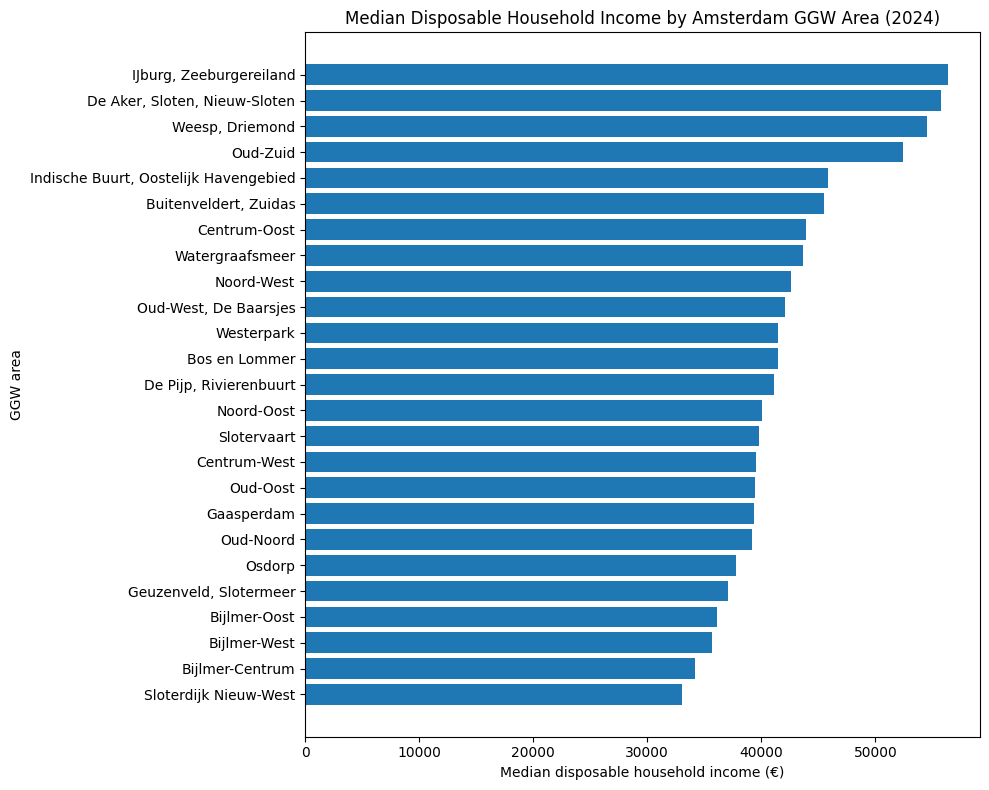

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the 2024 observations and sort by income
income_2024 = (
    income_df[income_df["Year"] == 2024]
    .sort_values(
        by="Median disposable household income (€)",
        ascending=True
    )
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 8))

plt.barh(
    income_2024["Name"],
    income_2024["Median disposable household income (€)"]
)

plt.xlabel("Median disposable household income (€)")
plt.ylabel("GGW area")
plt.title("Median Disposable Household Income by Amsterdam GGW Area (2024)")

plt.tight_layout()
plt.show()

# Missing values 

In [11]:
# Create all possible combinations of years and GGW areas
all_years = range(2011, 2025)
all_areas = income_df["Name"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_years, all_areas],
    names=["Year", "Name"]
)

# Reindex the dataset so that absent year-area combinations appear as NaN
complete_df = (
    income_df
    .set_index(["Year", "Name"])
    .reindex(complete_index)
    .reset_index()
)

# Identify missing observations
missing_data = complete_df[
    complete_df["Median disposable household income (€)"].isna()
]

print("Number of missing year-area observations:", len(missing_data))
print()
print(missing_data[["Year", "Name"]].to_string(index=False))

Number of missing year-area observations: 11

 Year                  Name
 2011 Sloterdijk Nieuw-West
 2011          Bijlmer-West
 2012 Sloterdijk Nieuw-West
 2012          Bijlmer-West
 2013 Sloterdijk Nieuw-West
 2013          Bijlmer-West
 2014 Sloterdijk Nieuw-West
 2014          Bijlmer-West
 2015 Sloterdijk Nieuw-West
 2016 Sloterdijk Nieuw-West
 2017 Sloterdijk Nieuw-West


There are 11 missing year-area observations: Bijlmer-West has no observations between 2011-2014, while Sloterdijk 
Nieuw-West has no observations between 2011-2017.